# 近岸海域水质评价与污染特征识别

<div align="center">课程设计 · 自拟题目（B 题 水环境方向）</div>

| | |
|---|---|
| **数据** | 和鲸社区公开数据集「水质检测数据2024」，2024 年海洋实测，3 699 条记录 / 1 359 个站位 |
| **范围** | 渤海、黄海、东海、南海；11 个沿海省份 + 近海背景站 |
| **标准** | GB 3097-1997《海水水质标准》 |
| **方法** | 单因子评价（最差因子定类）· 富营养化指数 E · 主成分分析（PCA） |
| **工具** | Python 3 · pandas · numpy · matplotlib · scipy |

> **运行方式**：在项目根目录启动 Jupyter，选择 `Kernel → Restart & Run All`。
> 数据文件为 `data/海洋水质监测2024.csv`（GBK 编码），图表输出到 `outputs/figures/`，
> 结果表输出到 `outputs/近岸海域水质评价结果.xlsx`。

## 目录

| 章节 | 内容 |
|---|---|
| 一 | 研究背景与问题 |
| 二 | 数据来源与清洗（含 187 行错列的发现与修复） |
| 三 | 单因子评价与类别构成 |
| 四 | 富营养化评价 |
| 五 | 空间分布特征 |
| 六 | 海区污染特征对比 |
| 七 | 主成分分析 |
| 八 | 月度变化 |
| 九 | 结果导出 |
| 十 | 结论与建议 |
| 十一 | 局限与复现说明 |

In [1]:
%matplotlib inline
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Polygon as MplPoly
from scipy.stats import chi2 as chi2_dist
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

In [2]:
BASE = os.getcwd()
DATA_DIR = os.path.join(BASE, "data")
OUT_DIR = os.path.join(BASE, "outputs")
FIG_DIR = os.path.join(OUT_DIR, "figures")
CSV_PATH = os.path.join(DATA_DIR, "海洋水质监测2024.csv")
LAND_PATH = os.path.join(DATA_DIR, "land_110m_clip.json")
XLSX_PATH = os.path.join(OUT_DIR, "近岸海域水质评价结果.xlsx")
MD_PATH = os.path.join(OUT_DIR, "结论摘要.md")

for d in (OUT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DengXian"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.edgecolor"] = "#5b6670"
plt.rcParams["axes.linewidth"] = 0.8

CLASS_NAMES = ["一类", "二类", "三类", "四类", "劣四类"]
CLASS_COLORS = ["#2E75B6", "#70AD47", "#FFC000", "#ED7D31", "#C00000"]
SEA_ORDER = ["渤海", "黄海", "东海", "南海"]

# GB 3097-1997 海水水质标准（mg/L）
# direction = "up" 表示浓度越高越差；"down" 表示数值越低越差（溶解氧）
FACTORS = [
    ("DO", "溶解氧", [6.0, 5.0, 4.0, 3.0], "down"),
    ("COD", "化学需氧量", [2.0, 3.0, 4.0, 5.0], "up"),
    ("DIN", "无机氮", [0.20, 0.30, 0.40, 0.50], "up"),
    ("DIP", "活性磷酸盐", [0.015, 0.030, 0.045, 0.050], "up"),
    ("oil", "石油类", [0.05, 0.05, 0.30, 0.50], "up"),
]
FACTOR_LABEL = {k: lab for k, lab, _, _ in FACTORS}
FACTOR_LABEL["pH"] = "pH"
FACTOR_ORDER = ["DO", "COD", "DIN", "DIP", "oil", "pH"]

MONTH_ABBR = {m: i + 1 for i, m in enumerate(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])}

assert os.path.exists(CSV_PATH), "未找到数据文件，请在项目根目录（含 data/ 文件夹）启动 Jupyter"
print("项目根目录：", BASE)
print("图表输出目录：", FIG_DIR)

项目根目录： D:\vscode\pythoncode\WaterPolution
图表输出目录： D:\vscode\pythoncode\WaterPolution\outputs\figures


## 一、研究背景与问题

近岸海域是陆地与海洋相互作用最强烈的区域，也是人口、航运、养殖和工业活动最集中的地带。入海河流与直排口把大量氮、磷和有机质带入近岸水体，在潮汐、径流和地形共同作用下，容易形成**富营养化—赤潮—溶解氧下降**的连锁反应。因此，弄清近岸海域的水质类别、主要污染因子及其空间分布，是海洋环境管理的基础工作。

GB 3097-1997《海水水质标准》把海水分为一~四类，评价时按**最差因子定类**。但仅看类别还不够：氮磷浓度即使未使类别降级，也可能已推动水体走向富营养化。因此本项目在单因子评价之外，再叠加**富营养化指数 E** 与**主成分分析（PCA）**，从“类别—风险—来源”三个层面刻画污染特征。

围绕三个问题展开：

1. **水质状况**：2024 年近岸海域水质类别如何构成？优良率与劣四类比例是多少？
2. **主要污染因子**：哪个因子最常成为“拖后腿”的因子？其超标率如何？
3. **空间特征**：污染在四大海区、各省份和站位尺度上如何分布？热点在哪里？

技术路线：

```
数据清洗 → 单因子评价（GB 3097-1997）→ 富营养化指数 → 空间制图
        → 海区/省份对比 → PCA 主导因子识别 → 结论与建议
```

## 二、数据来源与清洗

### 2.1 数据概况

数据集来自和鲸社区公开数据集「水质检测数据2024」，为 2024 年海洋水质实测数据，共 14 个字段：

| 字段 | 含义 | 单位 / 示例 |
|---|---|---|
| 海区 | 所属海区 | 渤海 / 黄海 / 东海 / 南海 |
| 省份 | 沿海省份 | 辽宁、山东、浙江……（另有“近海”背景站） |
| 地市 | 地级市 | 丹东、大连…… |
| 点位编码 | 站位编号 | `LNH06001` |
| 实测经度 / 实测纬度 | 站位坐标 | 123.97 / 39.73 |
| 监测时间 | 监测月份 | `Nov-24` |
| pH(无量纲) | 酸碱度 | 8.25 |
| 溶解氧(mg/L) | DO | 9.21 |
| 化学需氧量(mg/L) | COD | 0.84 |
| 无机氮(mg/L) | DIN | 0.109 |
| 活性磷酸盐(mg/L) | DIP | 0.008（或“未检出”） |
| 石油类(mg/L) | 石油类 | 0.01 |
| 水质类别 | 数据自带的评价结果 | 一类 / 第二类 / 劣四类…… |

覆盖范围：**3 699 条记录、1 359 个站位、4 个海区、11 个沿海省份 + 近海背景站、6 个月份**（4、5、7、8、10、11 月）。

> 注意：文件是 **GBK 编码**，直接用 UTF-8 读取会乱码。

In [3]:
raw = pd.read_csv(CSV_PATH, encoding="gbk", dtype=str)
raw.columns = [c.strip().replace("\ufeff", "") for c in raw.columns]
print(f"数据规模：{raw.shape[0]} 行 × {raw.shape[1]} 列")
raw.head(5)

数据规模：3699 行 × 14 列


,海区,省份,地市,点位编码,实测经度,实测纬度,监测时间,pH(无量纲),溶解氧(mg/L),化学需氧量(mg/L),无机氮(mg/L),活性磷酸盐(mg/L),石油类(mg/L),水质类别
0,黄海,辽宁,丹东,LNH06001,123.97,39.73,Nov-24,8.25,9.21,0.84,0.109,未检出,0.01,一类
1,黄海,辽宁,丹东,LNH06002,123.7,39.7,Nov-24,8.14,8.78,0.87,0.13,0.008,0.013,一类
2,黄海,辽宁,丹东,LNH06003,123.65,39.49,Oct-24,8.12,6.77,0.77,0.038,0.006,0.005,一类
3,黄海,辽宁,丹东,LNH06004,124.12,39.73,Nov-24,8.14,9.09,0.88,0.278,0.003,0.009,二类
4,黄海,辽宁,丹东,LNH06005,124.03,39.53,Oct-24,8.1,6.49,0.71,0.06,0.007,0.007,一类


### 2.2 五个数据质量问题

1. **编码问题**：文件为 GBK，需显式指定 `encoding="gbk"`。
2. **187 行整体错列（最关键）**：所有“近海”背景站记录缺少“地市”字段，导致 `点位编码 → 经度 → 纬度 → 监测时间 → pH` 依次左移一格，`pH` 列被写入一个额外的化学需氧量数值，`溶解氧/化学需氧量` 变成空值。
3. **类别命名混用**：同一列里既有“一类/二类”，也有“第一类/第二类”，还有“劣四类”，需要统一映射为 1~5。
4. **“未检出”**：`活性磷酸盐`、`石油类`、`溶解氧`、`化学需氧量` 中存在“未检出”，属于低于检出限，按 0 参与评价；`pH` 的“未检出”按缺失处理。
5. **时间字段**：`Nov-24` 这类英文月份缩写需转换；且数据**只有 6 个月**，并非全年 12 个月，结论只能代表监测期。

先看看错列长什么样——这些行的 `实测纬度` 存的是 `Jul-24` 这样的月份字符串，这就是错列的“指纹”：

In [4]:
bad = pd.to_numeric(raw["实测纬度"], errors="coerce").isna() & raw["省份"].eq("近海")
print(f"疑似错列行数：{bad.sum()}")
raw.loc[bad, ["海区", "省份", "地市", "点位编码", "实测经度",
              "实测纬度", "监测时间", "pH(无量纲)", "无机氮(mg/L)"]].head(5)

疑似错列行数：187


,海区,省份,地市,点位编码,实测经度,实测纬度,监测时间,pH(无量纲),无机氮(mg/L)
2340,渤海,近海,JHB00201,121.08,40.16,Jul-24,8.06,1.07,0.018
2341,渤海,近海,JHB00705,121.47,40.53,Jul-24,8.16,1.74,0.142
2342,渤海,近海,JHB01209,118.9,38.67,Jul-24,8.09,1.17,0.011
2343,渤海,近海,JHB01210,118.47,38.64,Jul-24,8.06,1.38,0.028
2344,渤海,近海,JHB00601,120.27,38.2,Jul-24,8.03,0.82,0.032


### 2.3 清洗规则

对上述 187 行按“**整体左移一格**”回填：

| 错列后的列 | 真实含义 |
|---|---|
| 地市 | 点位编码 |
| 点位编码 | 实测经度 |
| 实测经度 | 实测纬度 |
| 实测纬度 | 监测时间 |
| 监测时间 | pH |
| pH(无量纲) | 化学需氧量（额外的那个数值） |
| 溶解氧、化学需氧量 | 置为缺失（该批近海站未测） |

**为什么判定 pH 列里那个数值是 COD 而不是溶解氧？** 把它当 COD 时，用国标复算的类别与该批数据自带类别一致率为 93%；当溶解氧时一致率只有 0.5%（因为 0.2~1.8 mg/L 的“溶解氧”会把几乎所有站位判成劣四类）。数值量级（0.2~1.8 mg/L）也与 COD 吻合。

下面先定义各步骤函数：

In [5]:
def read_raw(path: str) -> pd.DataFrame:
    """读取 GBK 编码的原始 CSV。"""
    df = pd.read_csv(path, encoding="gbk", dtype=str)
    df.columns = [c.strip().replace("\ufeff", "") for c in df.columns]
    return df

def repair_block_shift(df: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    """修复「近海」背景站数据块的整体错列。

    原始文件中 187 行「近海」记录的“地市”字段缺失，导致 点位编码/经度/纬度/时间/pH
    依次左移一格，同时 pH 列被写入一个额外的化学需氧量数值。识别依据是这些行的
    “实测纬度”不是数字（存的是月份字符串）。修复后：
        点位编码 <- 地市     实测经度 <- 点位编码    实测纬度 <- 实测经度
        监测时间 <- 实测纬度   pH <- 监测时间         化学需氧量 <- pH
        溶解氧 置空（原始数据未测）
    """
    bad = pd.to_numeric(df["实测纬度"], errors="coerce").isna() & df["省份"].eq("近海")
    n = int(bad.sum())
    if n == 0:
        return df, 0

    t = df.loc[bad, ["地市", "点位编码", "实测经度", "实测纬度", "监测时间", "pH(无量纲)"]].copy()
    df.loc[bad, "点位编码"] = t["地市"]
    df.loc[bad, "实测经度"] = t["点位编码"]
    df.loc[bad, "实测纬度"] = t["实测经度"]
    df.loc[bad, "监测时间"] = t["实测纬度"]
    df.loc[bad, "pH(无量纲)"] = t["监测时间"]
    df.loc[bad, "化学需氧量(mg/L)"] = t["pH(无量纲)"]
    df.loc[bad, "溶解氧(mg/L)"] = np.nan
    df.loc[bad, "地市"] = ""
    return df, n

def to_num(series: pd.Series, zero_undetected: bool = True) -> pd.Series:
    """转数值：'未检出' 记为 0（低于检出限，按 0 参与评价），空串为缺失。"""
    s = series.astype(str).str.strip()
    repl = {"": np.nan, "nan": np.nan, "NaN": np.nan, "—": np.nan, "-": np.nan}
    if zero_undetected:
        repl["未检出"] = "0"
    s = s.replace(repl)
    return pd.to_numeric(s, errors="coerce")

def normalize_class(series: pd.Series) -> pd.Series:
    """'第一类' / '一类' / '劣四类' -> 1 / 2 / 3 / 4 / 5。"""
    s = series.astype(str).str.strip().str.replace("第", "", regex=False).str.replace("类", "", regex=False)
    mp = {"一": 1, "二": 2, "三": 3, "四": 4, "劣四": 5}
    return s.map(mp)

def parse_month(series: pd.Series) -> pd.Series:
    s = series.astype(str).str.strip()
    return s.str[:3].map(MONTH_ABBR)

In [6]:
def load_data(path: str) -> tuple[pd.DataFrame, dict]:
    """读取 -> 修复错列 -> 数值化 -> 去重，返回分析用长表与清洗日志。"""
    raw = read_raw(path)
    raw, n_shift = repair_block_shift(raw)

    df = pd.DataFrame({
        "海区": raw["海区"].str.strip(),
        "省份": raw["省份"].str.strip(),
        "地市": raw["地市"].fillna("").str.strip(),
        "点位编码": raw["点位编码"].str.strip(),
        "经度": pd.to_numeric(raw["实测经度"], errors="coerce"),
        "纬度": pd.to_numeric(raw["实测纬度"], errors="coerce"),
        "mon": parse_month(raw["监测时间"]),
        "pH": pd.to_numeric(raw["pH(无量纲)"].replace("未检出", np.nan), errors="coerce"),
        "DO": to_num(raw["溶解氧(mg/L)"]),
        "COD": to_num(raw["化学需氧量(mg/L)"]),
        "DIN": to_num(raw["无机氮(mg/L)"]),
        "DIP": to_num(raw["活性磷酸盐(mg/L)"]),
        "oil": to_num(raw["石油类(mg/L)"]),
        "class_given": normalize_class(raw["水质类别"]),
    })

    n_raw = len(df)
    bad_geo = df["经度"].isna() | df["纬度"].isna() | df["mon"].isna()
    df = df.loc[~bad_geo].copy()

    dup_key = df.duplicated(subset=["点位编码", "mon"], keep="first")
    n_dup = int(dup_key.sum())
    df = df.loc[~dup_key].copy()

    df["月份"] = df["mon"].astype(int)
    df["年"] = 2024

    log = {
        "原始记录": n_raw,
        "错列修复行": n_shift,
        "坐标/时间无效剔除": int(bad_geo.sum()),
        "重复记录剔除": n_dup,
        "有效记录": len(df),
        "站位数": df["点位编码"].nunique(),
        "海区数": df["海区"].nunique(),
        "月份": sorted(df["月份"].unique().tolist()),
    }
    return df, log


df, log = load_data(CSV_PATH)
pd.DataFrame({"指标": list(log.keys()), "数值": [str(v) for v in log.values()]})

,指标,数值
0,原始记录,3699
1,错列修复行,187
2,坐标/时间无效剔除,0
3,重复记录剔除,0
4,有效记录,3699
5,站位数,1359
6,海区数,4
7,月份,"[4, 5, 7, 8, 10, 11]"


### 2.4 清洗结果

- 3 699 条记录全部保留：坐标、时间均落在合理范围，也没有“站点 + 月份”重复记录；
- 187 行错列全部归位，恢复到 187 个真实的近海站位；
- “未检出”按 0 处理，类别统一为 1~5。

抽查修复后的近海站记录，可以看到点位编码、经纬度、月份、pH、COD 都已回到正确位置：

In [7]:
cols = ["海区", "省份", "点位编码", "经度", "纬度", "月份", "pH", "COD", "DO", "DIN"]
df[df["省份"] == "近海"][cols].head(5)

,海区,省份,点位编码,经度,纬度,月份,pH,COD,DO,DIN
2340,渤海,近海,JHB00201,121.08,40.16,7,8.06,1.07,NaN,0.018
2341,渤海,近海,JHB00705,121.47,40.53,7,8.16,1.74,NaN,0.142
2342,渤海,近海,JHB01209,118.90,38.67,7,8.09,1.17,NaN,0.011
2343,渤海,近海,JHB01210,118.47,38.64,7,8.06,1.38,NaN,0.028
2344,渤海,近海,JHB00601,120.27,38.20,7,8.03,0.82,NaN,0.032


## 三、单因子评价与类别构成

### 3.1 方法

海水水质类别由**最差因子**决定：

$$C = \max_{i \in \{DO,\ COD,\ DIN,\ DIP,\ oil,\ pH\}} C_i$$

各因子的一~四类限值（GB 3097-1997）：

| 因子 | 一类 | 二类 | 三类 | 四类 | 方向 |
|---|---|---|---|---|---|
| 溶解氧 DO (mg/L) | 6 | 5 | 4 | 3 | 越低越差 |
| 化学需氧量 COD (mg/L) | 2 | 3 | 4 | 5 | 越高越差 |
| 无机氮 DIN (mg/L) | 0.20 | 0.30 | 0.40 | 0.50 | 越高越差 |
| 活性磷酸盐 DIP (mg/L) | 0.015 | 0.030 | 0.045 | 0.050 | 越高越差 |
| 石油类 (mg/L) | 0.05 | 0.05 | 0.30 | 0.50 | 越高越差 |
| pH | 7.8~8.5 | 7.8~8.5 | 6.8~8.8 | 6.8~8.8 | 区间外变差 |

超过四类限值记为“劣四类”（第 5 级）。同时计算污染指数 $P_i = C_i / S_{i,1}$（溶解氧取 $S_{i,1}/C_i$），用于在类别并列时判定“首要污染因子”。

In [8]:
def classify(value: float, limits: list, direction: str) -> float:
    """按标准限值定类：1~4 类，超过四类限值记 5（劣四类），缺失记 NaN。"""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return np.nan
    if direction == "up":
        for i, lim in enumerate(limits):
            if value <= lim:
                return i + 1
    else:
        for i, lim in enumerate(limits):
            if value >= lim:
                return i + 1
    return 5

def classify_ph(ph: float) -> float:
    """GB 3097-1997 pH：一类/二类 7.8~8.5，三类/四类 6.8~8.8。"""
    if ph is None or (isinstance(ph, float) and np.isnan(ph)):
        return np.nan
    if 7.8 <= ph <= 8.5:
        return 1
    if 6.8 <= ph <= 8.8:
        return 3
    return 5

def evaluate(df: pd.DataFrame) -> pd.DataFrame:
    """逐条计算各因子类别、综合类别、首要污染因子与污染指数。"""
    out = df.copy()

    for key, _, limits, direction in FACTORS:
        out[f"cls_{key}"] = [classify(v, limits, direction) for v in out[key].to_numpy()]
    out["cls_pH"] = [classify_ph(v) for v in out["pH"].to_numpy()]

    cls_cols = [f"cls_{k}" for k in FACTOR_ORDER]
    cls_mat = out[cls_cols].to_numpy(dtype=float)
    out["class_calc"] = np.nanmax(np.where(np.isnan(cls_mat), -np.inf, cls_mat), axis=1)
    out.loc[~np.isfinite(out["class_calc"]), "class_calc"] = np.nan

    # 污染指数 Pi = Ci / S(一类)；溶解氧取 S / Ci（越大越差），pH 用类别近似
    for key, _, limits, direction in FACTORS:
        v = out[key].to_numpy(dtype=float)
        s1 = limits[0]
        with np.errstate(divide="ignore", invalid="ignore"):
            pi = v / s1 if direction == "up" else s1 / v
        out[f"pi_{key}"] = np.where(np.isfinite(pi), pi, np.nan)
    out["pi_pH"] = out["cls_pH"]

    # 首要污染因子：仅在超标（类别 ≥ 二类）样本中识别；
    # 取类别最高者，并列时取污染指数最大者
    pi_cols = [f"pi_{k}" for k in FACTOR_ORDER]
    pi_mat = out[pi_cols].to_numpy(dtype=float)
    cls_fill = np.where(np.isnan(cls_mat), -np.inf, cls_mat)
    max_cls = cls_fill.max(axis=1)
    pi_fill = np.where(np.isnan(pi_mat), -np.inf, pi_mat)
    pi_fill = np.where(np.abs(cls_mat - max_cls[:, None]) < 1e-9, pi_fill, -np.inf)
    idx = np.argmax(pi_fill, axis=1)
    labels = np.array([FACTOR_LABEL[k] for k in FACTOR_ORDER])
    out["首要因子"] = np.where(max_cls >= 2, labels[idx], "")
    out.loc[~np.isfinite(max_cls), "首要因子"] = ""

    out["综合评价"] = out["class_calc"].map(lambda c: CLASS_NAMES[int(c) - 1] if pd.notna(c) else "")
    out["给定类别"] = out["class_given"].map(lambda c: CLASS_NAMES[int(c) - 1] if pd.notna(c) else "")
    out["类别一致"] = out["class_calc"].eq(out["class_given"])
    return out

In [9]:
df = evaluate(df)
df[["点位编码", "DO", "COD", "DIN", "DIP", "oil",
    "class_calc", "综合评价", "首要因子", "给定类别"]].head(5)

,点位编码,DO,COD,DIN,DIP,oil,class_calc,综合评价,首要因子,给定类别
0,LNH06001,9.21,0.84,0.109,0.000,0.010,1.0,一类,,一类
1,LNH06002,8.78,0.87,0.130,0.008,0.013,1.0,一类,,一类
2,LNH06003,6.77,0.77,0.038,0.006,0.005,1.0,一类,,一类
3,LNH06004,9.09,0.88,0.278,0.003,0.009,2.0,二类,无机氮,二类
4,LNH06005,6.49,0.71,0.060,0.007,0.007,1.0,一类,,一类


### 3.2 类别构成

In [10]:
def class_table(df: pd.DataFrame) -> pd.DataFrame:
    counts = df["class_calc"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    pct = counts / counts.sum() * 100
    return pd.DataFrame({
        "水质类别": CLASS_NAMES,
        "样本数": counts.to_numpy(),
        "占比(%)": pct.round(2).to_numpy(),
    })


tab = class_table(df)
display(tab)
print(f"优良率（一类 + 二类）：{df['class_calc'].isin([1, 2]).mean() * 100:.1f}%")

,水质类别,样本数,占比(%)
0,一类,2085,56.37
1,二类,710,19.19
2,三类,254,6.87
3,四类,137,3.70
4,劣四类,513,13.87


优良率（一类 + 二类）：75.6%


In [11]:
def _style(ax, grid_axis="y"):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis=grid_axis, ls="--", lw=0.6, color="#cfd6dc", alpha=0.8)
    ax.set_axisbelow(True)

def _draw_land(ax, land):
    for ring in land:
        ax.add_patch(MplPoly(ring, closed=True, facecolor="#F3F0E9", edgecolor="#A9B2B9",
                             linewidth=0.45, zorder=1))

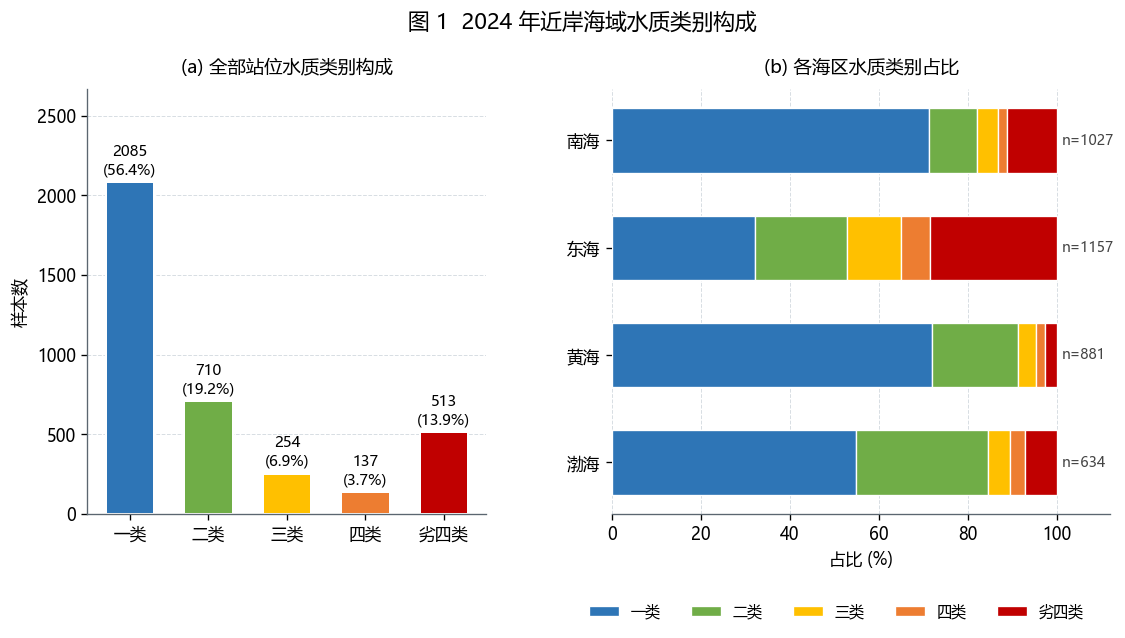

In [12]:
def fig_class_composition(df: pd.DataFrame, path: str):
    tab = class_table(df)
    fig = plt.figure(figsize=(11, 4.6))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.25], wspace=0.28)

    ax = fig.add_subplot(gs[0, 0])
    bars = ax.bar(tab["水质类别"], tab["样本数"], color=CLASS_COLORS, width=0.62,
                  edgecolor="white", linewidth=1.2)
    for b, n, p in zip(bars, tab["样本数"], tab["占比(%)"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 25, f"{n}\n({p:.1f}%)",
                ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("样本数")
    ax.set_title("(a) 全部站位水质类别构成", fontsize=11, pad=10)
    ax.set_ylim(0, tab["样本数"].max() * 1.28)
    _style(ax)

    ax2 = fig.add_subplot(gs[0, 1])
    ct = pd.crosstab(df["海区"], df["class_calc"]).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
    ct = ct.reindex([s for s in SEA_ORDER if s in ct.index])
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    left = np.zeros(len(pct))
    for i, (name, color) in enumerate(zip(CLASS_NAMES, CLASS_COLORS), start=1):
        ax2.barh(pct.index, pct[i], left=left, color=color, label=name, height=0.6,
                 edgecolor="white", linewidth=0.8)
        left += pct[i].to_numpy()
    for y, (idx, row) in enumerate(pct.iterrows()):
        ax2.text(101, y, f"n={ct.loc[idx].sum()}", va="center", fontsize=8.5, color="#444")
    ax2.set_xlim(0, 112)
    ax2.set_xlabel("占比 (%)")
    ax2.set_title("(b) 各海区水质类别占比", fontsize=11, pad=10)
    ax2.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.18), frameon=False, fontsize=9)
    _style(ax2, grid_axis="x")
    ax2.spines["left"].set_visible(False)

    fig.suptitle("图 1  2024 年近岸海域水质类别构成", fontsize=13, y=1.02)
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig_class_composition(df, os.path.join(FIG_DIR, "fig1_水质类别构成.png"))

**图 1 读图**

- 全部样本中：一类 2 085 条（56.4%）、二类 710 条（19.2%）、三类 254 条（6.9%）、四类 137 条（3.7%）、劣四类 513 条（13.9%）；**优良率 75.6%，劣四类 13.9%**。
- 海区差异非常明显：**东海**优良率仅 52.9%、劣四类 28.4%，是四个海区中最差的；**黄海**最好（优良率 91.3%、劣四类仅 2.6%）；渤海、南海居中（84.5% / 82.1%）。
- 从堆叠条看，东海的红色段明显长于其他海区，说明污染不是个别站位，而是区域性问题。

### 3.3 与数据自带类别的校验

将复算类别与原始 `水质类别` 交叉比对，可检验清洗与定类逻辑是否可靠：

In [13]:
ct = pd.crosstab(df["class_calc"], df["class_given"])
ct.index = [CLASS_NAMES[int(i) - 1] for i in ct.index]
ct.columns = [CLASS_NAMES[int(i) - 1] for i in ct.columns]
display(ct)
print(f"类别一致率：{df['类别一致'].mean() * 100:.1f}%")

,一类,二类,三类,四类,劣四类
一类,2066,19,0,0,0
二类,0,710,0,0,0
三类,0,0,193,61,0
四类,0,0,0,134,3
劣四类,0,0,0,0,513


类别一致率：97.8%


一致率 **97.8%**，对角线以外的少量差异主要来自四舍五入和数据源自身的评价口径差异。这说明：

1. 187 行错列的修复是正确的（否则一致率会显著下降）；
2. 限值表与“最差因子定类”的实现无误；
3. 后续所有统计、制图都建立在这套可信的评价结果上。

## 四、富营养化评价

### 4.1 指数与分级

海洋领域常用的富营养化指数：

$$E = \frac{COD \times DIN \times DIP \times 10^6}{4500}$$

其中 COD、DIN、DIP 单位均为 mg/L；$E \geq 1$ 即判定为富营养化。分级：

| E | < 1 | 1 ~ 3 | 3 ~ 9 | ≥ 9 |
|---|---|---|---|---|
| 等级 | 贫营养 | 轻度富营养 | 中度富营养 | 重度富营养 |

相比单因子评价，E 把三种污染物“合起来”看：只要氮、磷、有机质同时偏高，即使各自都没超标，E 也可能超过 1，从而提前预警。

In [14]:
def eutrophication(df: pd.DataFrame) -> pd.DataFrame:
    """E = COD × DIN × DIP × 10^6 / 4500，E ≥ 1 即富营养化。

    COD、DIN、DIP 单位均为 mg/L。分级：<1 贫营养；1~3 轻度；3~9 中度；≥9 重度。
    """
    out = df.copy()
    out["E"] = out["COD"] * out["DIN"] * out["DIP"] * 1e6 / 4500.0
    out.loc[out["COD"].isna() | out["DIN"].isna() | out["DIP"].isna(), "E"] = np.nan

    def grade(e):
        if pd.isna(e):
            return ""
        if e < 1:
            return "贫营养"
        if e < 3:
            return "轻度富营养"
        if e < 9:
            return "中度富营养"
        return "重度富营养"

    out["营养等级"] = out["E"].map(grade)
    out["富营养化"] = out["E"] >= 1
    return out

df = eutrophication(df)
grades = ["贫营养", "轻度富营养", "中度富营养", "重度富营养"]
cnt = df["营养等级"].value_counts().reindex(grades).to_frame("样本数")
cnt["占比(%)"] = (cnt["样本数"] / len(df) * 100).round(1)
display(cnt)
print(f"E≥1（富营养化）占比：{df['E'].ge(1).mean() * 100:.1f}%")
print(f"E≥9（重度富营养）占比：{df['E'].ge(9).mean() * 100:.1f}%")

,样本数,占比(%)
营养等级,,
贫营养,2901,78.4
轻度富营养,355,9.6
中度富营养,181,4.9
重度富营养,262,7.1


E≥1（富营养化）占比：21.6%
E≥9（重度富营养）占比：7.1%


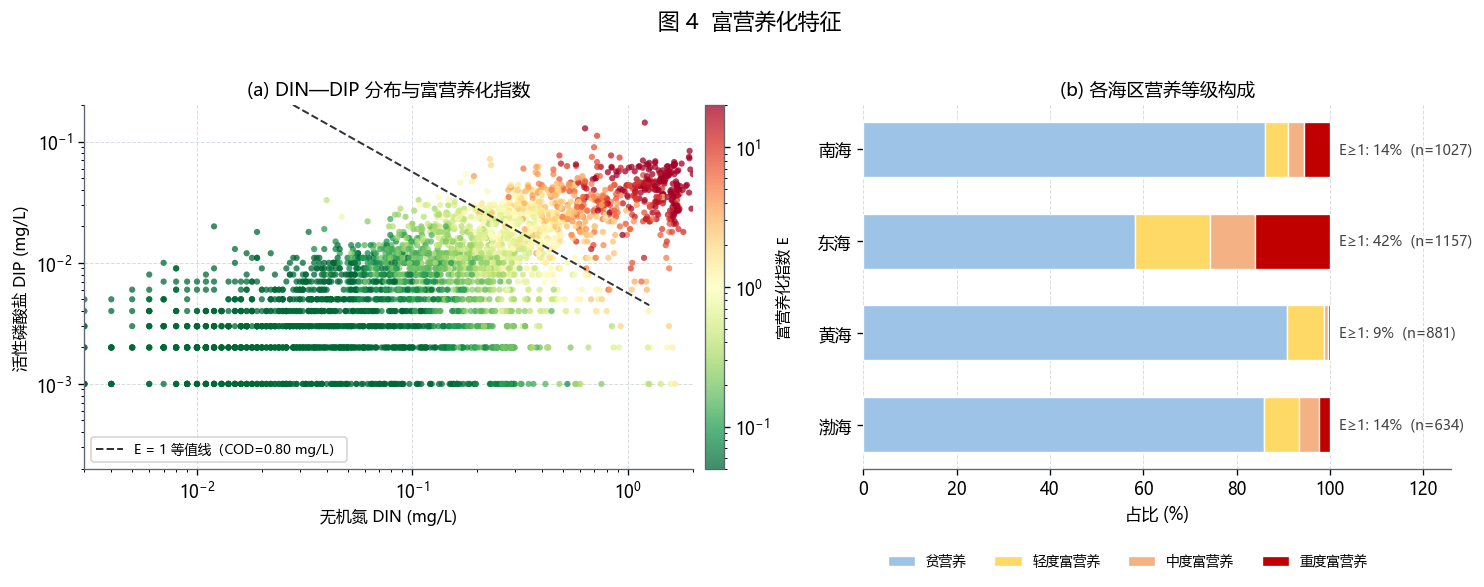

In [15]:
def fig_eutrophication(df: pd.DataFrame, path: str):
    fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.9), gridspec_kw={"width_ratios": [1.1, 1]})

    ax = axes[0]
    sub = df.dropna(subset=["E", "DIN", "DIP"])
    sub = sub[(sub["DIN"] > 0) & (sub["DIP"] > 0)]
    sc = ax.scatter(sub["DIN"], sub["DIP"], c=sub["E"], s=14, cmap="RdYlGn_r",
                    norm=LogNorm(vmin=0.05, vmax=20), alpha=0.75, edgecolors="none")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("无机氮 DIN (mg/L)", fontsize=9.5)
    ax.set_ylabel("活性磷酸盐 DIP (mg/L)", fontsize=9.5)
    ax.set_title("(a) DIN—DIP 分布与富营养化指数", fontsize=11)

    cod_med = sub["COD"].median()
    x = np.logspace(-2, 0.1, 200)
    y = 4500 / (cod_med * x * 1e6)
    mask = (y > 1e-4) & (y < 0.3)
    ax.plot(x[mask], y[mask], "--", color="#333", lw=1.2,
            label=f"E = 1 等值线（COD={cod_med:.2f} mg/L）")
    ax.set_xlim(0.003, 2.0)
    ax.set_ylim(2e-4, 0.2)
    ax.legend(fontsize=8, loc="lower left")
    cb = fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label("富营养化指数 E", fontsize=9)
    _style(ax, grid_axis="both")

    ax = axes[1]
    seas = [s for s in SEA_ORDER if s in df["海区"].unique()]
    grades = ["贫营养", "轻度富营养", "中度富营养", "重度富营养"]
    gcolors = ["#9DC3E6", "#FFD966", "#F4B183", "#C00000"]
    ct = pd.crosstab(df["海区"], df["营养等级"]).reindex(seas).fillna(0)
    ct = ct.reindex(columns=grades, fill_value=0)
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    left = np.zeros(len(pct))
    for g, c in zip(grades, gcolors):
        ax.barh(pct.index, pct[g], left=left, color=c, label=g, height=0.6,
                edgecolor="white", linewidth=0.8)
        left += pct[g].to_numpy()
    for y, idx in enumerate(pct.index):
        n = int(ct.loc[idx].sum())
        e_rate = df[df["海区"] == idx]["E"].ge(1).mean() * 100
        ax.text(102, y, f"E≥1: {e_rate:.0f}%  (n={n})", va="center", fontsize=8.5, color="#444")
    ax.set_xlim(0, 126)
    ax.set_xlabel("占比 (%)")
    ax.set_title("(b) 各海区营养等级构成", fontsize=11)
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.2), frameon=False, fontsize=8.2)
    _style(ax, grid_axis="x")
    ax.spines["left"].set_visible(False)

    fig.suptitle("图 4  富营养化特征", fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig_eutrophication(df, os.path.join(FIG_DIR, "fig4_富营养化特征.png"))

**图 4 读图**

- E≥1 的样本占 **21.6%**，重度富营养（E≥9）占 7.1%，整体上“大部分贫营养、少数重度富营养”的两极分化明显。
- 海区上，**东海 41.8% 的样本富营养化**，远高于渤海（14.0%）、南海（13.9%）和黄海（9.3%）。
- 左图散点沿右上方向聚集：DIN > 0.2 mg/L 且 DIP > 0.02 mg/L 的点基本都落在 E=1 等值线之上，说明**氮磷双高**是富营养化的直接推手。
- 这也解释了为什么长江口—杭州湾、珠江口一带既“类别差”又“营养盐高”。

## 五、空间分布特征

### 5.1 站位汇总

先把 6 个月的记录按站位聚合：取全年**最差类别**代表该站水质状况，同时计算 DIN、DIP、E 的均值与富营养化率。

In [16]:
def station_summary(df: pd.DataFrame) -> pd.DataFrame:
    def agg_station(d: pd.DataFrame) -> pd.Series:
        cls = d["class_calc"].dropna()
        worst = int(cls.max()) if len(cls) else np.nan
        mode = d.loc[d["首要因子"].ne(""), "首要因子"].mode()
        return pd.Series({
            "海区": d["海区"].iloc[0],
            "省份": d["省份"].iloc[0],
            "经度": d["经度"].mean(),
            "纬度": d["纬度"].mean(),
            "监测次数": len(d),
            "最差类别": worst,
            "平均类别": round(float(cls.mean()), 2) if len(cls) else np.nan,
            "DIN均值": round(float(d["DIN"].mean()), 3),
            "DIP均值": round(float(d["DIP"].mean()), 4),
            "COD均值": round(float(d["COD"].mean()), 3),
            "E均值": round(float(d["E"].mean()), 3),
            "富营养化率(%)": round(float(d["E"].ge(1).mean() * 100), 1),
            "主要因子": mode.iloc[0] if len(mode) else "",
        })

    return df.groupby("点位编码").apply(agg_station).reset_index()


st = station_summary(df)
display(st.head(5))
print(f"站位数：{len(st)}")

,点位编码,海区,省份,经度,纬度,监测次数,最差类别,平均类别,DIN均值,DIP均值,COD均值,E均值,富营养化率(%),主要因子
0,FJD01001,东海,福建,120.360000,26.330000,3,1,1.00,0.110,0.0097,0.400,0.126,0.0,
1,FJD01002,东海,福建,119.666667,26.110000,3,5,2.67,0.339,0.0083,0.763,0.478,0.0,无机氮
2,FJD01003,东海,福建,119.883333,26.073333,3,2,1.67,0.180,0.0090,0.477,0.229,0.0,无机氮
3,FJD01004,东海,福建,119.670000,25.866667,3,2,1.67,0.129,0.0077,0.683,0.185,0.0,无机氮
4,FJD01005,东海,福建,120.020000,25.820000,3,1,1.00,0.098,0.0080,0.573,0.125,0.0,


站位数：1359


### 5.2 空间分布图

底图为 Natural Earth 110m 简化陆地轮廓（离线文件 `data/land_110m_clip.json`），无需联网即可复现。

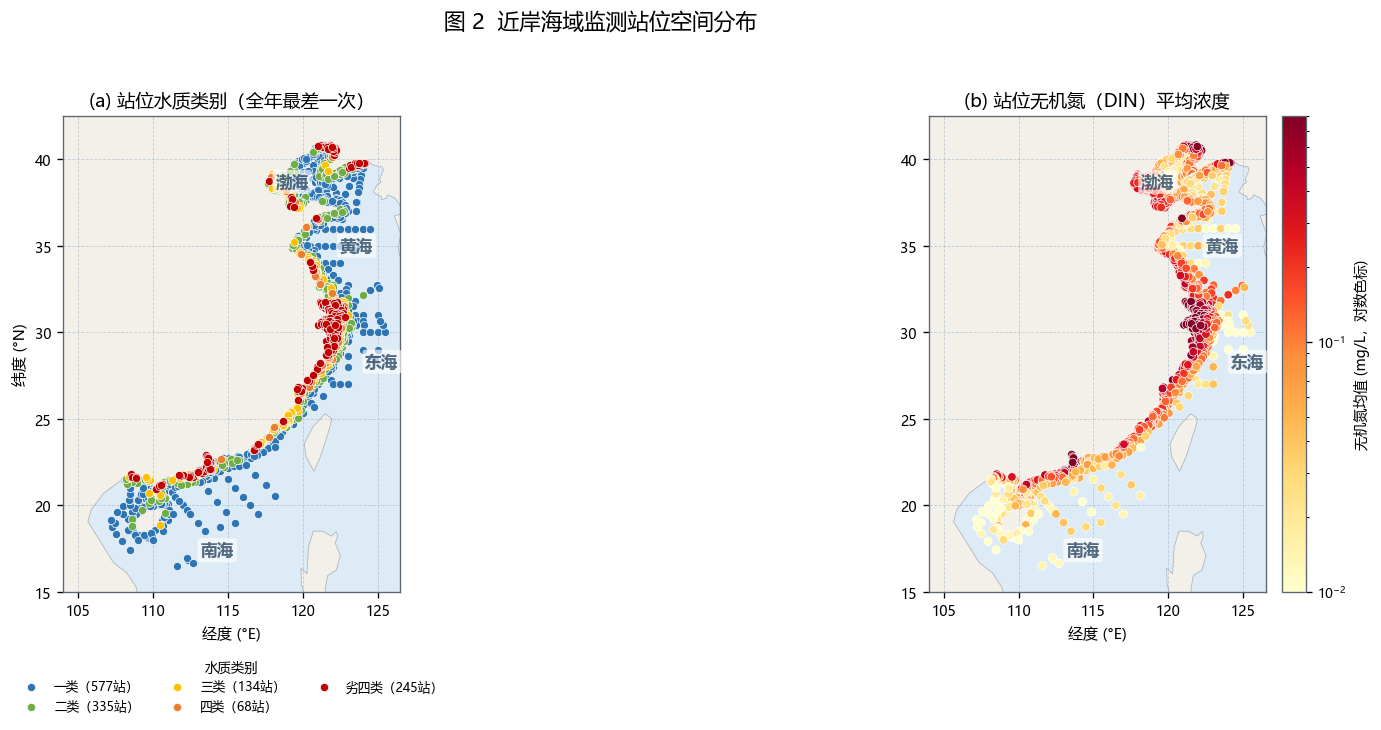

In [17]:
def fig_spatial(st: pd.DataFrame, path: str):
    land = json.load(open(LAND_PATH, encoding="utf-8"))
    fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.2))

    for ax in axes:
        ax.set_facecolor("#DCEBF5")
        _draw_land(ax, land)
        ax.set_xlim(104, 126.5)
        ax.set_ylim(15, 42.5)
        ax.set_aspect(1.0 / np.cos(np.deg2rad(30)))
        ax.set_xticks(range(105, 130, 5))
        ax.set_yticks(range(15, 45, 5))
        ax.grid(ls="--", lw=0.5, color="#9fb4c4", alpha=0.6)
        ax.tick_params(labelsize=8.5)
        ax.set_xlabel("经度 (°E)", fontsize=9)
    axes[0].set_ylabel("纬度 (°N)", fontsize=9)

    ax = axes[0]
    for cls, color, name in zip([1, 2, 3, 4, 5], CLASS_COLORS, CLASS_NAMES):
        sub = st[st["最差类别"] == cls]
        ax.scatter(sub["经度"], sub["纬度"], s=24, c=color, edgecolors="white",
                   linewidths=0.4, label=f"{name}（{len(sub)}站）", zorder=3)
    ax.set_title("(a) 站位水质类别（全年最差一次）", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=7.6,
              frameon=False, title="水质类别", title_fontsize=8)

    ax = axes[1]
    sub = st.dropna(subset=["DIN均值"])
    sc = ax.scatter(sub["经度"], sub["纬度"], c=sub["DIN均值"], s=26,
                    cmap="YlOrRd", norm=LogNorm(vmin=0.01, vmax=0.8),
                    edgecolors="white", linewidths=0.4, zorder=3)
    cb = fig.colorbar(sc, ax=ax, orientation="vertical", fraction=0.035, pad=0.02)
    cb.set_label("无机氮均值 (mg/L，对数色标)", fontsize=8.5)
    cb.ax.tick_params(labelsize=8)
    ax.set_title("(b) 站位无机氮（DIN）平均浓度", fontsize=11)

    for ax in axes:
        for name, (x, y) in {"渤海": (119.3, 38.7), "黄海": (123.6, 35.0),
                             "东海": (125.3, 28.3), "南海": (114.3, 17.4)}.items():
            ax.text(x, y, name, fontsize=10, color="#33506a", alpha=0.85,
                    ha="center", va="center", fontweight="bold", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.65))

    fig.suptitle("图 2  近岸海域监测站位空间分布", fontsize=13, y=0.99)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig_spatial(st, os.path.join(FIG_DIR, "fig2_站位空间分布.png"))

**图 2 读图**

- **“近岸高、离岸低”的梯度非常清晰**：一类站位（蓝色）多分布在离岸较远、水交换较好的海域；劣四类（红色）几乎贴着海岸线，集中在长江口—杭州湾、珠江口、渤海湾和辽东湾。
- 按站位统计：一类 577 站、二类 335 站、三类 134 站、四类 68 站、劣四类 245 站——**近 1/5 的站位全年最差一次达到劣四类**。
- 右图 DIN 的空间格局与左图高度一致：长江口外、杭州湾、珠江口以及渤海湾西侧明显偏红（DIN > 0.3 mg/L），而黄海中部、东海离岸区偏黄（DIN < 0.1 mg/L）。
- 说明污染不是均匀分布，而是**由河口和半封闭海湾向内向外递减**，治理应“管住入海口”。

## 六、海区污染特征对比

从“因子超标率”和“首要因子构成”两个角度看四大海区的差异。

In [18]:
def sea_class_table(df: pd.DataFrame) -> pd.DataFrame:
    ct = pd.crosstab(df["海区"], df["class_calc"]).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
    ct = ct.reindex([s for s in SEA_ORDER if s in ct.index])
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    res = ct.copy()
    res.columns = [f"{c}样本数" for c in CLASS_NAMES]
    for i, name in enumerate(CLASS_NAMES, start=1):
        res[f"{name}占比(%)"] = pct[i].round(1).to_numpy()
    res["合计"] = ct.sum(axis=1).to_numpy()
    res["优良率(%)"] = ((ct[1] + ct[2]) / ct.sum(axis=1) * 100).round(1).to_numpy()
    res["劣四类率(%)"] = (ct[5] / ct.sum(axis=1) * 100).round(1).to_numpy()
    return res.reset_index()

def sea_summary(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby("海区")
    res = pd.DataFrame({
        "样本数": g.size(),
        "站位数": g["点位编码"].nunique(),
        "优良率(%)": g.apply(lambda d: (d["class_calc"].isin([1, 2]).mean() * 100)),
        "劣四类率(%)": g.apply(lambda d: (d["class_calc"].eq(5).mean() * 100)),
        "DIN均值": g["DIN"].mean(),
        "DIP均值": g["DIP"].mean(),
        "COD均值": g["COD"].mean(),
        "DO均值": g["DO"].mean(),
        "E均值": g["E"].mean(),
        "富营养化率(%)": g.apply(lambda d: d["E"].ge(1).mean() * 100),
    })
    for c in ["优良率(%)", "劣四类率(%)", "富营养化率(%)"]:
        res[c] = res[c].round(1)
    for c in ["DIN均值", "DIP均值", "COD均值", "DO均值", "E均值"]:
        res[c] = res[c].round(3)
    return res.reindex([s for s in SEA_ORDER if s in res.index]).reset_index()

def factor_summary(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for key in FACTOR_ORDER:
        lab = FACTOR_LABEL[key]
        cls = df[f"cls_{key}"]
        val = df["pH"] if key == "pH" else df[key]
        rows.append({
            "因子": lab,
            "有效样本": int(cls.notna().sum()),
            "均值": round(float(val.mean()), 4) if key != "pH" else round(float(val.mean()), 3),
            "最大值": round(float(val.max()), 4) if key != "pH" else round(float(val.max()), 3),
            "超一类率(%)": round(float(cls.gt(1).mean() * 100), 1),
            "超二类率(%)": round(float(cls.gt(2).mean() * 100), 1),
            "超三类率(%)": round(float(cls.gt(3).mean() * 100), 1),
            "劣四类率(%)": round(float(cls.eq(5).mean() * 100), 1),
            "首要因子次数": int(df["首要因子"].eq(lab).sum()),
        })
    res = pd.DataFrame(rows)
    n_bad = int(df["class_calc"].ge(2).sum())
    res["首要因子占比(%)"] = (res["首要因子次数"] / max(n_bad, 1) * 100).round(1)
    res.attrs["n_bad"] = n_bad
    return res

def month_summary(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby("月份")
    res = pd.DataFrame({
        "样本数": g.size(),
        "优良率(%)": g.apply(lambda d: d["class_calc"].isin([1, 2]).mean() * 100).round(1),
        "劣四类率(%)": g.apply(lambda d: d["class_calc"].eq(5).mean() * 100).round(1),
        "DIN均值": g["DIN"].mean().round(3),
        "DIP均值": g["DIP"].mean().round(4),
        "E均值": g["E"].mean().round(3),
        "富营养化率(%)": g.apply(lambda d: d["E"].ge(1).mean() * 100).round(1),
    })
    return res.reset_index()

sea_tab = sea_class_table(df)
sea_sum = sea_summary(df)
fac_sum = factor_summary(df)
mon_sum = month_summary(df)

display(sea_sum)
display(fac_sum)

,海区,样本数,站位数,优良率(%),劣四类率(%),DIN均值,DIP均值,COD均值,DO均值,E均值,富营养化率(%)
0,渤海,634,240,84.5,7.1,0.212,0.006,1.384,8.034,1.615,14.0
1,黄海,881,325,91.3,2.6,0.152,0.007,0.969,7.749,0.432,9.3
2,东海,1157,417,52.9,28.4,0.430,0.022,0.938,6.983,5.676,41.8
3,南海,1027,377,82.1,11.3,0.201,0.008,0.782,6.473,1.609,13.9


,因子,有效样本,均值,最大值,超一类率(%),超二类率(%),超三类率(%),劣四类率(%),首要因子次数,首要因子占比(%)
0,溶解氧,3512,7.2000,13.460,6.1,0.4,0.1,0.0,103,6.4
1,化学需氧量,3699,0.9783,14.400,6.0,1.4,0.7,0.4,27,1.7
2,无机氮,3699,0.2628,5.333,36.6,23.6,17.2,13.5,1154,71.5
3,活性磷酸盐,3699,0.0119,0.144,25.8,10.0,3.4,2.4,329,20.4
4,石油类,3699,0.0076,0.059,0.1,0.1,0.0,0.0,1,0.1
5,pH,3699,8.0630,8.830,0.7,0.7,0.0,0.0,0,0.0


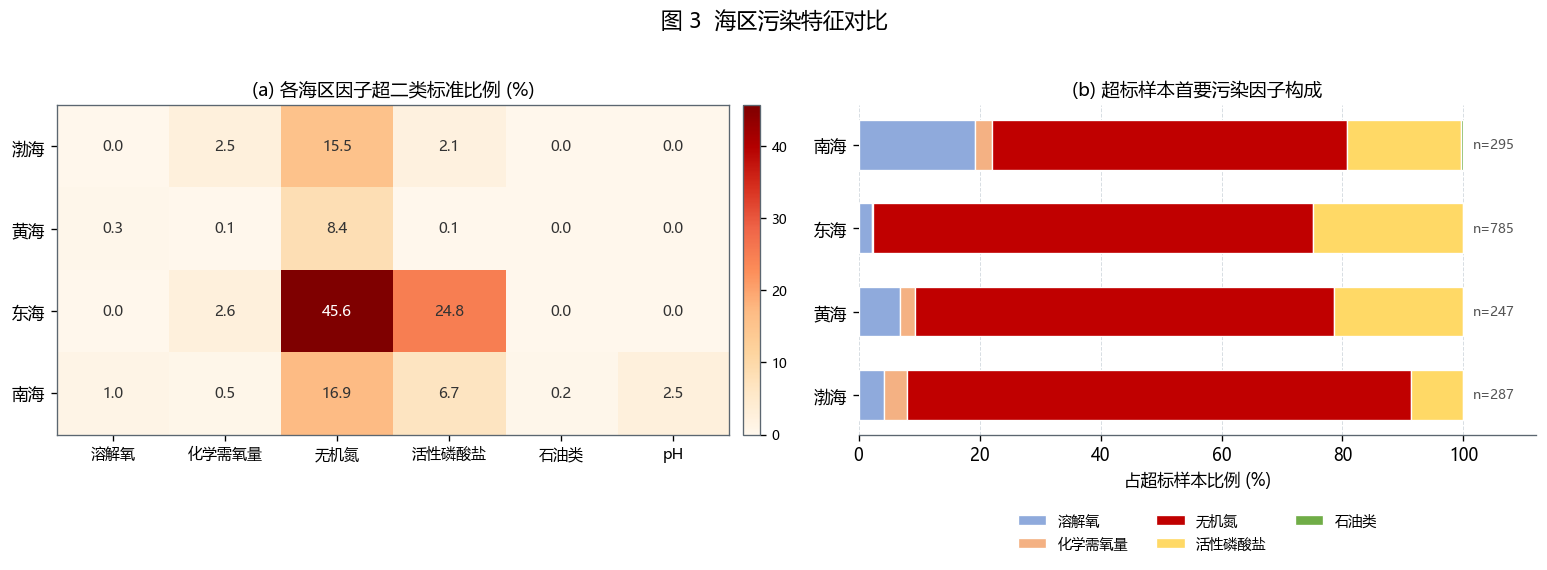

In [19]:
def fig_sea_compare(df: pd.DataFrame, path: str):
    seas = [s for s in SEA_ORDER if s in df["海区"].unique()]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.05, 1]})

    ax = axes[0]
    mat = np.zeros((len(seas), len(FACTOR_ORDER)))
    for i, s in enumerate(seas):
        sub = df[df["海区"] == s]
        for j, k in enumerate(FACTOR_ORDER):
            mat[i, j] = sub[f"cls_{k}"].gt(2).mean() * 100
    im = ax.imshow(mat, cmap="OrRd", vmin=0, vmax=max(10, mat.max()), aspect="auto")
    ax.set_xticks(range(len(FACTOR_ORDER)))
    ax.set_xticklabels([FACTOR_LABEL[k] for k in FACTOR_ORDER], fontsize=9)
    ax.set_yticks(range(len(seas)))
    ax.set_yticklabels(seas, fontsize=10)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i, j]:.1f}", ha="center", va="center", fontsize=9,
                    color="white" if mat[i, j] > mat.max() * 0.6 else "#333333")
    ax.set_title("(a) 各海区因子超二类标准比例 (%)", fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02).ax.tick_params(labelsize=8)

    ax = axes[1]
    bad = df[df["class_calc"].ge(2)]
    ct = pd.crosstab(bad["海区"], bad["首要因子"]).reindex(seas).fillna(0)
    ct = ct.drop(columns=[""], errors="ignore")
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    left = np.zeros(len(pct))
    factor_colors = {"溶解氧": "#8FAADC", "化学需氧量": "#F4B183", "无机氮": "#C00000",
                     "活性磷酸盐": "#FFD966", "石油类": "#70AD47", "pH": "#B4A7D6"}
    for f in FACTOR_ORDER:
        lab = FACTOR_LABEL[f]
        if lab not in pct.columns:
            continue
        ax.barh(pct.index, pct[lab], left=left, color=factor_colors[lab], label=lab,
                height=0.6, edgecolor="white", linewidth=0.8)
        left += pct[lab].to_numpy()
    for y, idx in enumerate(pct.index):
        ax.text(101.5, y, f"n={int(ct.loc[idx].sum())}", va="center", fontsize=8, color="#555")
    ax.set_xlim(0, 112)
    ax.set_xlabel("占超标样本比例 (%)")
    ax.set_title("(b) 超标样本首要污染因子构成", fontsize=11)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False, fontsize=8.5)
    _style(ax, grid_axis="x")
    ax.spines["left"].set_visible(False)

    fig.suptitle("图 3  海区污染特征对比", fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig_sea_compare(df, os.path.join(FIG_DIR, "fig3_海区污染特征对比.png"))

**图 3 读图**

- 左图（超二类标准比例）显示：东海的 **无机氮 45.6%、活性磷酸盐 24.8%**，两项都远高于其他海区；黄海、渤海、南海的超标主要集中在无机氮（8.4%~16.9%）。
- 右图（超标样本的首要因子）：四个海区都是**无机氮占绝对主导**（东海 78%、渤海 83%、黄海 79%、南海 79%），东海还有约 20% 的样本以活性磷酸盐为首要因子。
- 南海有约 17% 的超标样本以**溶解氧**为首要因子，提示珠江口等区域存在耗氧问题，这是单纯看营养盐容易忽略的信息。
- 结论：**无机氮是四大海区共同的“头号因子”，东海是“氮磷双高”**，应作为优先控制区。

## 七、主成分分析

### 7.1 思路与适用性

把 DIN、DIP、COD、石油类 4 个污染指标放在一起做 PCA：

1. 先取对数 $\log_{10}(x + 10^{-4})$ 降低右偏，再 Z-score 标准化；
2. 计算相关系数矩阵、特征值与特征向量；
3. 用 **KMO 检验**和 **Bartlett 球形检验**判断是否适合做 PCA；
4. 用 **方差最大旋转（Varimax）**让载荷更易解释；
5. 按累计方差 ≥70% 保留主成分，载荷绝对值最大的指标即该主成分的“主导因子”。

In [20]:
def kmo_bartlett(Z: np.ndarray) -> tuple[float, float, float]:
    """返回 (总体 KMO, Bartlett 卡方, p 值)。Z 为标准化后的样本矩阵。"""
    R = np.corrcoef(Z, rowvar=False)
    p = R.shape[0]
    try:
        invR = np.linalg.inv(R)
    except np.linalg.LinAlgError:
        invR = np.linalg.pinv(R)
    d = np.sqrt(np.diag(invR))
    Q = -invR / np.outer(d, d)
    np.fill_diagonal(Q, 0.0)
    R0 = R.copy()
    np.fill_diagonal(R0, 0.0)
    num = np.sum(R0 ** 2)
    den = num + np.sum(Q ** 2)
    kmo = num / den if den > 0 else np.nan

    n = Z.shape[0]
    sign, logdet = np.linalg.slogdet(R)
    chi2 = -(n - 1 - (2 * p + 5) / 6) * logdet
    df = p * (p - 1) / 2
    from scipy.stats import chi2 as chi2_dist
    pval = chi2_dist.sf(chi2, df)
    return float(kmo), float(chi2), float(pval)

def varimax(phi: np.ndarray, gamma: float = 1.0, q: int = 200, tol: float = 1e-6) -> np.ndarray:
    p, k = phi.shape
    R = np.eye(k)
    d_old = 0.0
    for _ in range(q):
        L = phi @ R
        u, s, vh = np.linalg.svd(phi.T @ (L ** 3 - (gamma / p) * L @ np.diag(np.diag(L.T @ L))))
        R = u @ vh
        d = s.sum()
        if d_old != 0 and d / d_old < 1 + tol:
            break
        d_old = d
    return phi @ R

def pca_analysis(df: pd.DataFrame) -> dict:
    """对 DIN、DIP、COD、石油类 做 log 变换 + 标准化 + PCA（方差最大旋转）。"""
    vars_ = ["DIN", "DIP", "COD", "oil"]
    sub = df[vars_].dropna()
    X = np.log10(sub.to_numpy(dtype=float) + 1e-4)
    Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

    n, p = Z.shape
    R = np.corrcoef(Z, rowvar=False)
    eigval, eigvec = np.linalg.eigh(R)
    order = np.argsort(eigval)[::-1]
    eigval, eigvec = eigval[order], eigvec[:, order]
    eigval = np.clip(eigval, 0, None)

    loadings = eigvec * np.sqrt(eigval)
    scores = Z @ eigvec
    var_pct = eigval / eigval.sum() * 100
    cum_pct = np.cumsum(var_pct)

    # 保留特征值 > 1 的主成分；为便于解释，至少保留 2 个（4 个变量时前 2 个累计约 70%）
    n_comp = int(min(p, max(2, (eigval > 1).sum())))
    load_rot = varimax(loadings[:, :n_comp])
    for j in range(n_comp):
        if load_rot[np.argmax(np.abs(load_rot[:, j])), j] < 0:
            load_rot[:, j] *= -1
    rot_var = (load_rot ** 2).sum(axis=0) / p * 100

    kmo, chi2, pval = kmo_bartlett(Z)

    load_df = pd.DataFrame(load_rot, index=vars_, columns=[f"PC{i+1}" for i in range(n_comp)]).round(3)

    eig_df = pd.DataFrame({
        "主成分": [f"PC{i+1}" for i in range(n_comp)],
        "特征值": np.round(eigval[:n_comp], 3),
        "方差贡献率(%)": np.round(var_pct[:n_comp], 1),
        "累计贡献率(%)": np.round(cum_pct[:n_comp], 1),
        "旋转后贡献率(%)": np.round(rot_var, 1),
        "主导因子": [FACTOR_LABEL[vars_[int(np.argmax(np.abs(load_rot[:, i])))]]
                     for i in range(n_comp)],
    })

    score_df = pd.DataFrame(scores[:, :n_comp], index=sub.index,
                            columns=[f"PC{i+1}" for i in range(n_comp)])

    return {
        "n": n, "kmo": kmo, "chi2": chi2, "p": pval,
        "eigval": eigval, "var_pct": var_pct, "cum_pct": cum_pct,
        "loadings": load_df, "eig_df": eig_df, "scores": score_df,
        "loadings_raw": loadings, "vars": vars_,
    }

pca = pca_analysis(df)
display(pca["eig_df"])
display(pca["loadings"])
print(f"KMO = {pca['kmo']:.3f}；Bartlett χ² = {pca['chi2']:.1f}（p < 0.001）；n = {pca['n']}")

,主成分,特征值,方差贡献率(%),累计贡献率(%),旋转后贡献率(%),主导因子
0,PC1,1.831,45.8,45.8,41.5,活性磷酸盐
1,PC2,0.974,24.4,70.1,28.6,石油类


,PC1,PC2
DIN,0.872,0.227
DIP,0.892,-0.060
COD,0.321,0.607
oil,0.004,0.850


KMO = 0.529；Bartlett χ² = 2374.2（p < 0.001）；n = 3699


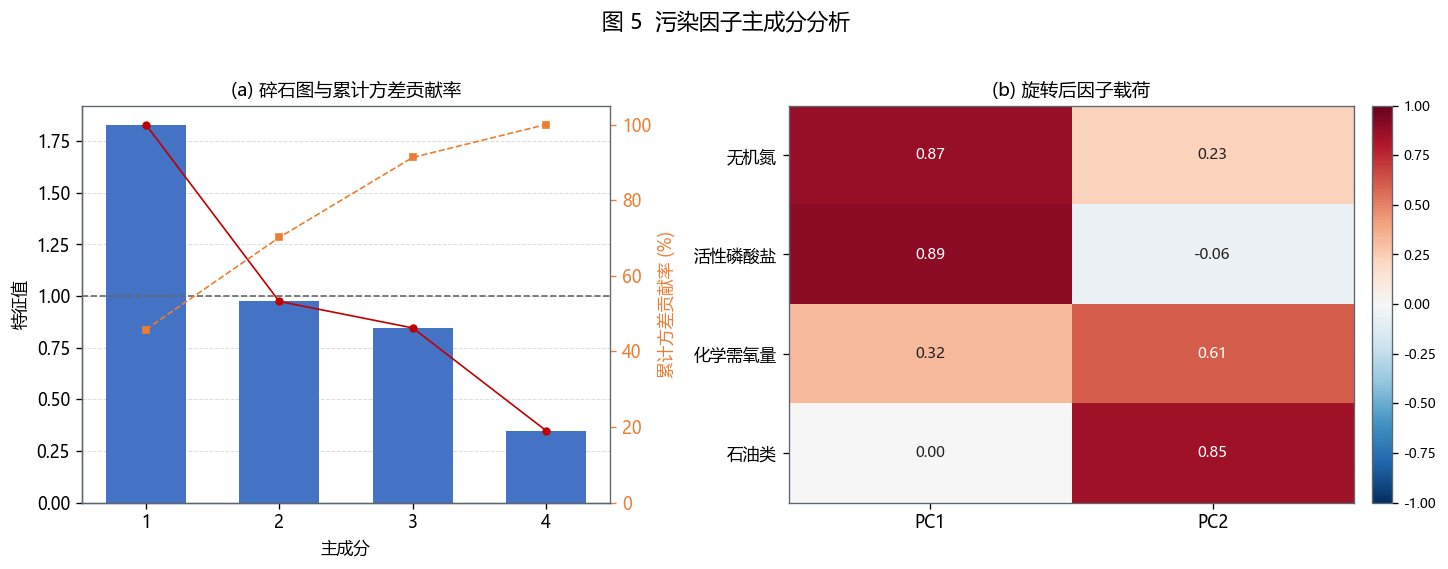

In [21]:
def fig_pca(pca: dict, path: str):
    fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6), gridspec_kw={"width_ratios": [1, 1.15]})

    ax = axes[0]
    k = len(pca["eigval"])
    x = np.arange(1, k + 1)
    ax.bar(x, pca["eigval"], color="#4472C4", width=0.6, label="特征值")
    ax.plot(x, pca["eigval"], "o-", color="#C00000", ms=4, lw=1, label="碎石曲线")
    ax.axhline(1, ls="--", color="#666", lw=1)
    ax.set_xticks(x)
    ax.set_xlabel("主成分")
    ax.set_ylabel("特征值")
    ax.set_title("(a) 碎石图与累计方差贡献率", fontsize=11)
    ax2 = ax.twinx()
    ax2.plot(x, pca["cum_pct"], "s--", color="#ED7D31", ms=4, lw=1)
    ax2.set_ylabel("累计方差贡献率 (%)", color="#ED7D31")
    ax2.tick_params(axis="y", colors="#ED7D31")
    ax2.set_ylim(0, 105)
    _style(ax)

    ax = axes[1]
    L = pca["loadings"]
    im = ax.imshow(L.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(L.shape[1]))
    ax.set_xticklabels(L.columns)
    ax.set_yticks(range(L.shape[0]))
    ax.set_yticklabels([FACTOR_LABEL[v] for v in L.index])
    for i in range(L.shape[0]):
        for j in range(L.shape[1]):
            v = L.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > 0.55 else "#222")
    ax.set_title("(b) 旋转后因子载荷", fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03).ax.tick_params(labelsize=8)

    fig.suptitle("图 5  污染因子主成分分析", fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig_pca(pca, os.path.join(FIG_DIR, "fig5_主成分分析.png"))

**图 5 读图**

- 碎石图：第 1 个主成分特征值 1.83，第 2 个 0.98；按累计方差 ≥70% 保留 2 个主成分，累计解释 **70.1%**（PC1 45.8%、PC2 24.4%）。
- **PC1**：活性磷酸盐（+0.89）、无机氮（+0.87）载荷最高 → 代表**营养盐污染（陆源氮磷输入）**；
- **PC2**：石油类（+0.85）、化学需氧量（+0.61）载荷最高 → 代表**有机污染（生活污水、石油类输入）**。
- KMO = 0.529（>0.5，勉强适合），Bartlett 检验 p < 0.001，说明指标间存在足够的相关性，降维是合理的。
- PCA 与单因子评价互相印证：近岸水质空间差异由“营养盐”和“有机污染”两条主线控制，而营养盐是第一主线。

## 八、月度变化

数据只覆盖 4、5、7、8、10、11 六个月，缺 1—3 月、6 月、9 月和 12 月，因此这里的“月度”只反映监测期内的变化，不能当全年季节规律。

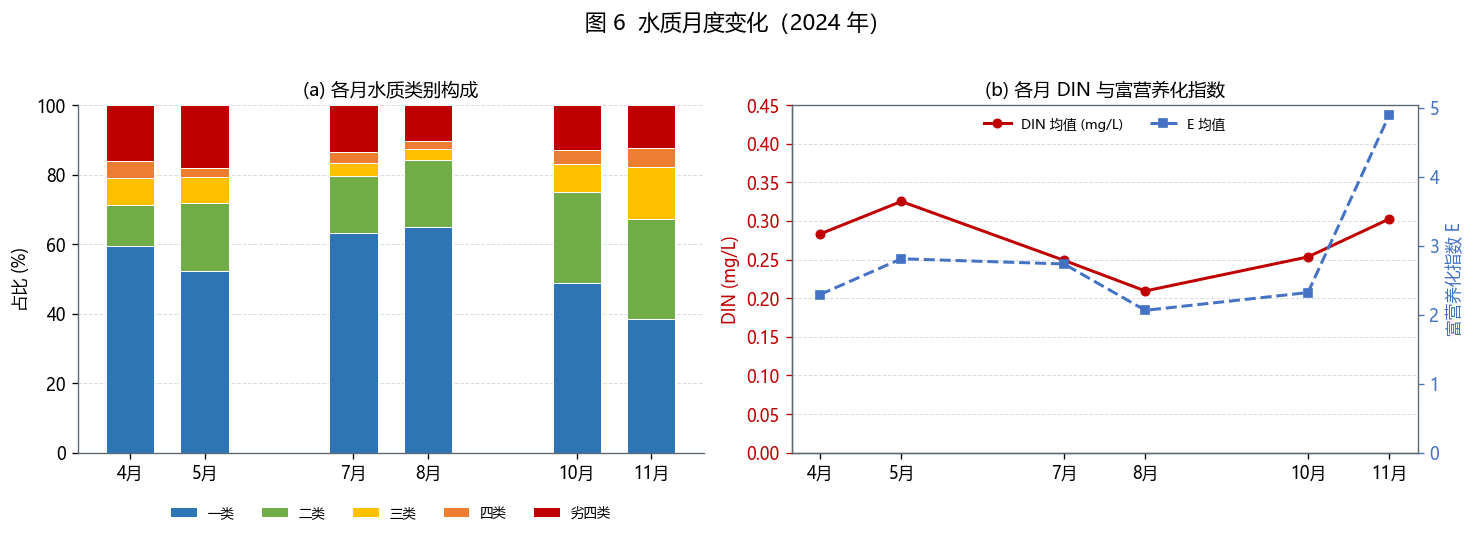

In [22]:
def fig_month(df: pd.DataFrame, path: str):
    months = sorted(df["月份"].unique())
    fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.4))

    ax = axes[0]
    ct = pd.crosstab(df["月份"], df["class_calc"]).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
    pct = ct.div(ct.sum(axis=1), axis=0) * 100
    bottom = np.zeros(len(pct))
    for i, (name, color) in enumerate(zip(CLASS_NAMES, CLASS_COLORS), start=1):
        ax.bar(pct.index, pct[i], bottom=bottom, color=color, label=name, width=0.65,
               edgecolor="white", linewidth=0.6)
        bottom += pct[i].to_numpy()
    ax.set_xticks(months)
    ax.set_xticklabels([f"{m}月" for m in months])
    ax.set_ylabel("占比 (%)")
    ax.set_ylim(0, 100)
    ax.set_title("(a) 各月水质类别构成", fontsize=11)
    ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    _style(ax)

    ax = axes[1]
    m = df.groupby("月份").agg(DIN=("DIN", "mean"), DIP=("DIP", "mean"), E=("E", "mean"))
    ax.plot(m.index, m["DIN"], "o-", color="#C00000", lw=1.8, ms=5, label="DIN 均值 (mg/L)")
    ax.set_xticks(months)
    ax.set_xticklabels([f"{m}月" for m in months])
    ax.set_ylabel("DIN (mg/L)", color="#C00000")
    ax.tick_params(axis="y", colors="#C00000")
    ax.set_ylim(0, max(0.45, m["DIN"].max() * 1.15))
    ax2 = ax.twinx()
    ax2.plot(m.index, m["E"], "s--", color="#4472C4", lw=1.8, ms=5, label="E 均值")
    ax2.set_ylabel("富营养化指数 E", color="#4472C4")
    ax2.tick_params(axis="y", colors="#4472C4")
    ax2.set_ylim(bottom=0)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper center", ncol=2, frameon=False)
    ax.set_title("(b) 各月 DIN 与富营养化指数", fontsize=11)
    _style(ax)

    fig.suptitle("图 6  水质月度变化（2024 年）", fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


fig_month(df, os.path.join(FIG_DIR, "fig6_月度变化.png"))

**图 6 读图**

- 7、8 月一类占比最高（约 63%），劣四类占比最低；4、5 月与 10、11 月劣四类占比相对更高。这与“夏季降水多、水体交换强、稀释作用明显”相符，但也可能与各月采样站位不同有关，解读时要谨慎。
- 右图 DIN 在 5 月最高（约 0.32 mg/L）、8 月最低（约 0.21 mg/L）；E 在 11 月出现明显抬升，说明**秋季部分海域营养盐与有机质同步升高**，值得后续加密监测。

## 九、结果导出

把明细、站位汇总、海区统计、因子统计、月度统计和 PCA 结果写入一个 Excel 工作簿，并生成可直接粘进报告的结论摘要。

In [23]:
def _write_sheet(writer, name, df, freeze="A2", widths=None, pct_cols=None):
    df.to_excel(writer, sheet_name=name, index=False, startrow=1)
    ws = writer.sheets[name]
    ncol = len(df.columns)
    from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
    from openpyxl.utils import get_column_letter

    title = ws.cell(row=1, column=1)
    title.value = name
    title.font = Font(name="微软雅黑", size=12, bold=True, color="FFFFFF")
    title.fill = PatternFill("solid", fgColor="2F5597")
    title.alignment = Alignment(horizontal="left", vertical="center")
    ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=max(ncol, 1))
    ws.row_dimensions[1].height = 22

    header_fill = PatternFill("solid", fgColor="D9E2F3")
    header_font = Font(name="微软雅黑", size=9, bold=True)
    thin = Side(style="thin", color="BFBFBF")
    for c in range(1, ncol + 1):
        cell = ws.cell(row=2, column=c)
        cell.font = header_font
        cell.fill = header_fill
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        cell.border = Border(bottom=thin)
    for r in range(3, ws.max_row + 1):
        for c in range(1, ncol + 1):
            ws.cell(row=r, column=c).font = Font(name="微软雅黑", size=9)

    if widths:
        for i, w in enumerate(widths, start=1):
            ws.column_dimensions[get_column_letter(i)].width = w
    else:
        for i in range(1, ncol + 1):
            vals = [str(ws.cell(row=r, column=i).value or "") for r in range(2, min(ws.max_row, 200) + 1)]
            ws.column_dimensions[get_column_letter(i)].width = min(22, max(9, max(len(v) for v in vals) * 1.6))

    ws.freeze_panes = freeze
    ws.auto_filter.ref = f"A2:{ws.cell(row=ws.max_row, column=ncol).coordinate}"

def export_excel(df, st, sea_tab, sea_sum, fac_sum, mon_sum, pca, log, path):
    from openpyxl.styles import Alignment
    detail_cols = ["海区", "省份", "地市", "点位编码", "经度", "纬度", "月份",
                   "pH", "DO", "COD", "DIN", "DIP", "oil", "E", "营养等级",
                   "cls_DO", "cls_COD", "cls_DIN", "cls_DIP", "cls_oil", "cls_pH",
                   "综合评价", "给定类别", "类别一致", "首要因子"]
    det = df[detail_cols].rename(columns={
        "DO": "溶解氧", "COD": "化学需氧量", "oil": "石油类", "E": "富营养化指数E",
        "cls_DO": "溶解氧类别", "cls_COD": "化学需氧量类别", "cls_DIN": "无机氮类别",
        "cls_DIP": "活性磷酸盐类别", "cls_oil": "石油类类别", "cls_pH": "pH类别",
        "综合评价": "评价类别", "给定类别": "数据自带类别", "类别一致": "与自带类别一致",
    })

    info = pd.DataFrame({
        "项目": ["数据集", "数据来源", "评价标准", "评价方法", "评价指标",
                 "原始记录数", "错列修复行数", "无效坐标/时间剔除", "重复记录剔除",
                 "有效记录数", "监测站位数", "覆盖海区", "监测月份",
                 "类别一致率", "生成时间"],
        "说明": [
            "海洋水质监测2024.csv（GBK 编码）",
            "和鲸社区公开数据集「水质检测数据2024」",
            "GB 3097-1997《海水水质标准》一~四类",
            "单因子评价（最差因子定类）+ 富营养化指数 + PCA",
            "pH、溶解氧、化学需氧量、无机氮、活性磷酸盐、石油类",
            log["原始记录"], log["错列修复行"], log["坐标/时间无效剔除"], log["重复记录剔除"],
            log["有效记录"], log["站位数"], "、".join(SEA_ORDER), "、".join(f"{m}月" for m in log["月份"]),
            f"{df['类别一致'].mean()*100:.1f}%",
            pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
        ],
    })

    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        _write_sheet(writer, "00_说明", info, widths=[22, 52])
        _write_sheet(writer, "01_明细评价", det)
        _write_sheet(writer, "02_站位汇总", st)
        _write_sheet(writer, "03_海区类别统计", sea_tab)
        _write_sheet(writer, "04_海区综合统计", sea_sum)
        _write_sheet(writer, "05_因子统计", fac_sum)
        _write_sheet(writer, "06_月度统计", mon_sum)
        _write_sheet(writer, "07_PCA特征值", pca["eig_df"])
        _write_sheet(writer, "08_PCA载荷", pca["loadings"].reset_index().rename(columns={"index": "指标"}))

        # 停靠表头：明细表冻结前 4 列 + 表头
        ws = writer.sheets["01_明细评价"]
        ws.freeze_panes = "E3"
        ws.auto_filter.ref = f"A2:{ws.cell(row=ws.max_row, column=ws.max_column).coordinate}"
        for row in ws.iter_rows(min_row=3, min_col=8, max_col=13):
            for c in row:
                c.number_format = "0.0000"

export_excel(df, st, sea_tab, sea_sum, fac_sum, mon_sum, pca, log, XLSX_PATH)
print("已输出：", XLSX_PATH)

已输出： D:\vscode\pythoncode\WaterPolution\outputs\近岸海域水质评价结果.xlsx


In [24]:
def build_report(df, st, sea_tab, sea_sum, fac_sum, mon_sum, pca, log) -> str:
    n = len(df)
    good = df["class_calc"].isin([1, 2]).mean() * 100
    bad4 = df["class_calc"].eq(5).mean() * 100
    e_rate = df["E"].ge(1).mean() * 100

    lines = []
    lines.append("# 近岸海域水质评价与污染特征识别——结论摘要\n")
    lines.append(f"> 数据：和鲸社区「水质检测数据2024」海洋水质实测，2024 年；有效记录 **{n}** 条、"
                 f"站位 **{log['站位数']}** 个、海区 **4** 个（渤海、黄海、东海、南海）。\n")
    lines.append("## 一、数据清洗\n")
    lines.append(f"- 原始记录 {log['原始记录']} 条；修复「近海」背景站整体错列 **{log['错列修复行']}** 行"
                 f"（地市字段缺失导致列左移）；剔除无效坐标/时间 {log['坐标/时间无效剔除']} 条、"
                 f"重复记录 {log['重复记录剔除']} 条。")
    lines.append(f"- 「未检出」按 0 参与评价（低于检出限）；水质类别统一为“一类~劣四类”。")
    lines.append(f"- 用 GB 3097-1997 单因子法复算的类别与数据自带类别一致率 **{df['类别一致'].mean()*100:.1f}%**，"
                 f"说明清洗与定类逻辑可靠。\n")

    lines.append("## 二、水质类别构成\n")
    tab = class_table(df)
    comp = "、".join([f"{r['水质类别']} {r['样本数']} 条（{r['占比(%)']:.1f}%）" for _, r in tab.iterrows()])
    lines.append(f"- 全部样本：{comp}。")
    lines.append(f"- **优良率（一、二类）{good:.1f}%，劣四类 {bad4:.1f}%**。\n")
    lines.append("| 海区 | 样本数 | 优良率(%) | 劣四类率(%) | DIN均值 | DIP均值 | E均值 | 富营养化率(%) |")
    lines.append("|---|---|---|---|---|---|---|---|")
    for _, r in sea_sum.iterrows():
        lines.append(f"| {r['海区']} | {r['样本数']} | {r['优良率(%)']} | {r['劣四类率(%)']} | "
                     f"{r['DIN均值']} | {r['DIP均值']} | {r['E均值']} | {r['富营养化率(%)']} |")
    lines.append("")

    lines.append("## 三、主要污染因子\n")
    n_bad = int(df["class_calc"].ge(2).sum())
    fac_sorted = fac_sum[fac_sum["首要因子次数"] > 0].sort_values("首要因子次数", ascending=False)
    desc = "、".join([f"**{r['因子']}** {r['首要因子次数']} 条（{r['首要因子占比(%)']}%）"
                     for _, r in fac_sorted.head(3).iterrows()])
    lines.append(f"- 在 {n_bad} 条超过一类标准的样本中，首要污染因子依次为：{desc}。")
    lines.append("- 各因子超二类标准比例："
                 + "；".join([f"{r['因子']} {r['超二类率(%)']}%" for _, r in fac_sum.iterrows()]) + "。")
    top1, top2 = fac_sorted.iloc[0]["因子"], fac_sorted.iloc[1]["因子"]
    lines.append(f"- 结论：**{top1}是近岸海域最主要的超标因子，{top2}次之**，二者共同构成富营养化的物质基础；"
                 "溶解氧、化学需氧量与石油类超标率均较低，水质问题以营养盐污染为主。\n")

    lines.append("## 四、空间分布特征\n")
    worst = sea_sum.sort_values("劣四类率(%)", ascending=False)
    lines.append("- 劣四类比例：" + "；".join([f"{r['海区']} {r['劣四类率(%)']}%" for _, r in worst.iterrows()]) + "。")
    lines.append(f"- 无机氮均值最高的海区为 **{sea_sum.sort_values('DIN均值', ascending=False).iloc[0]['海区']}**；"
                 f"富营养化率最高的海区为 **{sea_sum.sort_values('富营养化率(%)', ascending=False).iloc[0]['海区']}**。")
    prov = df[df['省份'] != '近海'].groupby('省份').agg(n=('class_calc', 'size'),
                                                       bad=('class_calc', lambda s: s.eq(5).mean() * 100))
    prov = prov[prov['n'] >= 30].sort_values('bad', ascending=False).head(5)
    lines.append("- 劣四类比例最高的省份（样本≥30）："
                 + "、".join([f"{i} {r['bad']:.1f}%" for i, r in prov.iterrows()]) + "。")
    lines.append("- 空间格局：**河口与半封闭海湾（长江口—杭州湾、珠江口、渤海湾、辽东湾）污染最重**，"
                 "离岸远、水交换好的站位以一类、二类为主，呈“近岸高、离岸低”的梯度。\n")

    lines.append("## 五、富营养化\n")
    lines.append(f"- E = COD×DIN×DIP×10⁶/4500，**E≥1 的样本占 {e_rate:.1f}%**；"
                 f"重度富营养（E≥9）占 {df['E'].ge(9).mean()*100:.1f}%。")
    lines.append(f"- 各海区富营养化率：" + "；".join([f"{r['海区']} {r['富营养化率(%)']}%" for _, r in sea_sum.iterrows()]) + "。\n")

    lines.append("## 六、主成分分析\n")
    ed = pca["eig_df"]
    L = pca["loadings"]
    lines.append(f"- KMO = {pca['kmo']:.3f}（>0.5，勉强适合），Bartlett 球形检验 χ² = {pca['chi2']:.1f}"
                 f"（p < 0.001），样本 n = {pca['n']}，可做主成分分析。")
    lines.append(f"- 按累计方差 ≥70% 准则保留前 {len(ed)} 个主成分，累计解释方差 "
                 f"**{ed['累计贡献率(%)'].iloc[-1]:.1f}%**："
                 + "；".join([f"{r['主成分']} {r['方差贡献率(%)']}%" for _, r in ed.iterrows()]) + "。")

    def _interp(col: str) -> str:
        top = set(L[col].abs().nlargest(2).index)
        if top <= {"DIN", "DIP"}:
            return "营养盐污染（陆源氮磷输入）"
        if top <= {"COD", "oil"}:
            return "有机污染（生活污水与石油类输入）"
        if "DO" in top:
            return "耗氧/缺氧过程"
        return "混合污染"

    for i in range(len(ed)):
        col = f"PC{i+1}"
        s = L[col].abs().sort_values(ascending=False)
        a, b = s.index[:2]
        lines.append(f"- {col}：载荷最高的是 {FACTOR_LABEL[a]}（{L.loc[a, col]:+.2f}）、"
                     f"{FACTOR_LABEL[b]}（{L.loc[b, col]:+.2f}），代表**{_interp(col)}**。")
    lines.append("- 解释：近岸水质空间差异主要由“陆源氮磷输入”与“有机污染”两条主线控制，"
                 "与单因子评价中无机氮、活性磷酸盐为主导因子的结论相互印证。\n")

    lines.append("## 七、结论与建议\n")
    lines.append(f"1. 2024 年近岸海域水质以一类、二类为主（优良率 {good:.1f}%），但劣四类仍占 {bad4:.1f}%，"
                 "污染集中在河口和半封闭海湾。")
    lines.append(f"2. {top1}为首要污染因子，富营养化风险以长江口、杭州湾、珠江口最突出，建议以**总氮/无机氮总量控制**为核心，"
                 "加强入海河流与直排口的氮磷协同减排。")
    lines.append("3. 渤海湾、辽东湾水交换能力弱，应控制养殖与陆源排放，关注夏季溶解氧下降风险。")
    lines.append("4. 数据仅覆盖 4、5、7、8、10、11 六个月，季节代表性有限，结论宜作趋势判断而非全年均值。\n")
    return "\n".join(lines)

report = build_report(df, st, sea_tab, sea_sum, fac_sum, mon_sum, pca, log)
with open(MD_PATH, "w", encoding="utf-8") as f:
    f.write(report)
display(Markdown(report))

# 近岸海域水质评价与污染特征识别——结论摘要

> 数据：和鲸社区「水质检测数据2024」海洋水质实测，2024 年；有效记录 **3699** 条、站位 **1359** 个、海区 **4** 个（渤海、黄海、东海、南海）。

## 一、数据清洗

- 原始记录 3699 条；修复「近海」背景站整体错列 **187** 行（地市字段缺失导致列左移）；剔除无效坐标/时间 0 条、重复记录 0 条。
- 「未检出」按 0 参与评价（低于检出限）；水质类别统一为“一类~劣四类”。
- 用 GB 3097-1997 单因子法复算的类别与数据自带类别一致率 **97.8%**，说明清洗与定类逻辑可靠。

## 二、水质类别构成

- 全部样本：一类 2085 条（56.4%）、二类 710 条（19.2%）、三类 254 条（6.9%）、四类 137 条（3.7%）、劣四类 513 条（13.9%）。
- **优良率（一、二类）75.6%，劣四类 13.9%**。

| 海区 | 样本数 | 优良率(%) | 劣四类率(%) | DIN均值 | DIP均值 | E均值 | 富营养化率(%) |
|---|---|---|---|---|---|---|---|
| 渤海 | 634 | 84.5 | 7.1 | 0.212 | 0.006 | 1.615 | 14.0 |
| 黄海 | 881 | 91.3 | 2.6 | 0.152 | 0.007 | 0.432 | 9.3 |
| 东海 | 1157 | 52.9 | 28.4 | 0.43 | 0.022 | 5.676 | 41.8 |
| 南海 | 1027 | 82.1 | 11.3 | 0.201 | 0.008 | 1.609 | 13.9 |

## 三、主要污染因子

- 在 1614 条超过一类标准的样本中，首要污染因子依次为：**无机氮** 1154 条（71.5%）、**活性磷酸盐** 329 条（20.4%）、**溶解氧** 103 条（6.4%）。
- 各因子超二类标准比例：溶解氧 0.4%；化学需氧量 1.4%；无机氮 23.6%；活性磷酸盐 10.0%；石油类 0.1%；pH 0.7%。
- 结论：**无机氮是近岸海域最主要的超标因子，活性磷酸盐次之**，二者共同构成富营养化的物质基础；溶解氧、化学需氧量与石油类超标率均较低，水质问题以营养盐污染为主。

## 四、空间分布特征

- 劣四类比例：东海 28.4%；南海 11.3%；渤海 7.1%；黄海 2.6%。
- 无机氮均值最高的海区为 **东海**；富营养化率最高的海区为 **东海**。
- 劣四类比例最高的省份（样本≥30）：上海 73.8%、浙江 32.0%、广东 17.0%、辽宁 11.3%、福建 7.3%。
- 空间格局：**河口与半封闭海湾（长江口—杭州湾、珠江口、渤海湾、辽东湾）污染最重**，离岸远、水交换好的站位以一类、二类为主，呈“近岸高、离岸低”的梯度。

## 五、富营养化

- E = COD×DIN×DIP×10⁶/4500，**E≥1 的样本占 21.6%**；重度富营养（E≥9）占 7.1%。
- 各海区富营养化率：渤海 14.0%；黄海 9.3%；东海 41.8%；南海 13.9%。

## 六、主成分分析

- KMO = 0.529（>0.5，勉强适合），Bartlett 球形检验 χ² = 2374.2（p < 0.001），样本 n = 3699，可做主成分分析。
- 按累计方差 ≥70% 准则保留前 2 个主成分，累计解释方差 **70.1%**：PC1 45.8%；PC2 24.4%。
- PC1：载荷最高的是 活性磷酸盐（+0.89）、无机氮（+0.87），代表**营养盐污染（陆源氮磷输入）**。
- PC2：载荷最高的是 石油类（+0.85）、化学需氧量（+0.61），代表**有机污染（生活污水与石油类输入）**。
- 解释：近岸水质空间差异主要由“陆源氮磷输入”与“有机污染”两条主线控制，与单因子评价中无机氮、活性磷酸盐为主导因子的结论相互印证。

## 七、结论与建议

1. 2024 年近岸海域水质以一类、二类为主（优良率 75.6%），但劣四类仍占 13.9%，污染集中在河口和半封闭海湾。
2. 无机氮为首要污染因子，富营养化风险以长江口、杭州湾、珠江口最突出，建议以**总氮/无机氮总量控制**为核心，加强入海河流与直排口的氮磷协同减排。
3. 渤海湾、辽东湾水交换能力弱，应控制养殖与陆源排放，关注夏季溶解氧下降风险。
4. 数据仅覆盖 4、5、7、8、10、11 六个月，季节代表性有限，结论宜作趋势判断而非全年均值。


In [25]:
print("本次生成的图表：")
for name in sorted(os.listdir(FIG_DIR)):
    p = os.path.join(FIG_DIR, name)
    print(f"  {name:28s} {os.path.getsize(p) / 1024:8.1f} KB")

本次生成的图表：
  fig1_水质类别构成.png                 103.4 KB
  fig2_站位空间分布.png                 371.5 KB
  fig3_海区污染特征对比.png               119.6 KB
  fig4_富营养化特征.png                 343.3 KB
  fig5_主成分分析.png                  137.7 KB
  fig6_月度变化.png                   120.5 KB


## 十、结论与建议

1. **水质总体尚可，但劣四类仍占一成以上。** 2024 年监测期近岸海域优良率 75.6%，劣四类 13.9%；东海最差（优良率 52.9%、劣四类 28.4%），黄海最好（91.3%、2.6%）。
2. **无机氮是头号污染因子。** 1 614 条超一类样本中，无机氮为首要因子的占 71.5%、活性磷酸盐占 20.4%；超二类率分别为 23.6% 和 10.0%，而 COD、石油类、pH 均低于 3%。
3. **污染集中在河口与半封闭海湾。** 长江口—杭州湾、珠江口、渤海湾、辽东湾是热点；上海劣四类率 73.8%、浙江 32.0%、广东 17.0%，呈“近岸高、离岸低”的梯度。
4. **富营养化风险不容忽视。** E≥1 占 21.6%，重度富营养占 7.1%；东海 41.8% 的样本富营养化，与氮磷双高直接相关。
5. **治理建议：** 以入海河流和直排口的**氮磷总量控制**为核心，优先治理长江口—杭州湾、珠江口；对渤海湾、辽东湾这类水交换弱的半封闭海湾，同步控制养殖投饵与陆源排放，并关注夏季溶解氧下降。

> 方法上的两点收获：① 用数据自带类别反校验复算结果（一致率 97.8%），让评价结论“有据可查”；② 单因子、E 指数、PCA 三种方法从不同侧面指向同一结论（无机氮主导），相互印证比单一指标更有说服力。

## 十一、局限与复现说明

### 11.1 局限

- **时间覆盖不足**：只有 4、5、7、8、10、11 六个月，无法刻画完整季节循环，结论应表述为“监测期”而非“全年平均”。
- **近海站缺溶解氧**：187 条近海背景站未测 DO，其类别由 COD、DIN、DIP、石油类判定；COD 由错列位置恢复，已在正文说明。
- **E 为经验指数**：只含 COD、DIN、DIP 三项，未考虑透明度、叶绿素 a、水温等，适合作相对比较，不宜直接对标营养状态分级标准。
- **底图为示意**：Natural Earth 110m 简化轮廓，仅用于展示空间格局，不用于距离/面积量算。
- **类别口径**：复算类别与数据自带类别存在约 2.2% 的差异，属于评价口径与舍入差异，不影响总体结论。

### 11.2 复现

```bash
pip install -r requirements.txt   # pandas / numpy / matplotlib / scipy / openpyxl / jupyter
jupyter notebook                  # 打开本文件，Kernel → Restart & Run All
```

运行顺序即本 Notebook 的单元格顺序；所有随机过程均无（PCA 为确定性特征分解），重复运行结果一致。输出文件：

```
outputs/
├─ figures/fig1~fig6 *.png
├─ 近岸海域水质评价结果.xlsx
└─ 结论摘要.md
```